# Practice Lab Assignment 1
## Neural Network Implementation from Scratch

### Objective
Implement a simple feedforward neural network from scratch in Python without using in-built deep learning libraries.


##

**Name:** Nahush Pramod Deshmukh  
**PRN:** 202502110006
**Batch:** A3  
**Course:** Generative AI Lab  
**Department:** CSE AIML

In [ ]:
# Importing the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

## 1. Problem Definition

The objective is to classify Iris flowers into one of three species:

- Setosa
- Versicolor
- Virginica

The classification is based on four input features:

- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

This is a multi-class classification problem.

In [ ]:
# Loading the Iris dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
# Inspect column data types, null values, and class balance before modeling

print("Dataset Information:")
print(df.info())

print("\nClass Distribution:")
print(df["species"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Class Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:
# Separate features (first 4 columns) from the target label (species)

X = df.iloc[:, :4].values
y = df["species"].values

# Map string class labels to integer one-hot encoding later
label_map = {
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
}

y = np.array([label_map[label] for label in y])

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (150, 4)
Target shape: (150,)


In [ ]:
# Train test split

indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))

train_idx = indices[:train_size]
test_idx = indices[train_size:]

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [ ]:
# Compute mean and std from the training data
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

# normalize both train and test sets
X_train = (X_train - train_mean) / train_std
X_test = (X_test - train_mean) / train_std

print("Normalized training data (first 5 rows):")
print(X_train[:5])

Normalized training data (first 5 rows):
[[ 0.35853593 -0.62179708  0.57995336  0.0355371 ]
 [-0.1248833   1.64615581 -1.10786563 -1.12749524]
 [ 2.29221285 -1.07538766  1.81768728  1.45702107]
 [ 0.23768112 -0.3950018   0.46743209  0.42321455]
 [ 1.20451958 -0.62179708  0.63621399  0.29398873]]


In [ ]:
# Convert integer class labels into one-hot vectors
def one_hot(y, num_classes):
    encoded = np.zeros((len(y), num_classes))
    encoded[np.arange(len(y)), y] = 1
    return encoded

y_train_onehot = one_hot(y_train, 3)
y_test_onehot = one_hot(y_test, 3)

print(y_train_onehot[:5])

[[0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 0.]]


In [ ]:
# ReLU activation for the hidden layer
def relu(x):
    return np.maximum(0, x)


# Derivative of ReLU, needed during backpropagation (1 where x > 0, else 0)
def relu_derivative(x):
    return (x > 0).astype(float)


# Softmax activation for the output layer: converts raw scores into class probabilities
# Subtracting row-wise max before exponentiating improves numerical stability
def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

## 2. Neural Network Architecture

The neural network has the following architecture:

Input Layer → Hidden Layer → Output Layer

4 neurons → 8 neurons → 3 neurons

- Input layer: 4 neurons
- Hidden layer: 8 neurons
- Output layer: 3 neurons
- Hidden layer activation: ReLU
- Output layer activation: Softmax
- Loss function: Cross-Entropy
- Optimization: Gradient Descent

In [ ]:
input_size = 4
hidden_size = 8
output_size = 3

# Weights are initialized with small random values (scaled by 0.01) so that
# neuron activations start small and the network does not saturate early.
# Biases start at zero, which is a standard, safe default.
W1 = np.random.randn(input_size, hidden_size) * 0.01
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.01
b2 = np.zeros((1, output_size))

print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

W1: (4, 8)
b1: (1, 8)
W2: (8, 3)
b2: (1, 3)


## 3. Forward Propagation

During forward propagation, the input data passes through the network.

First, the weighted sum is calculated for the hidden layer and ReLU activation is applied.

The hidden-layer output is then passed to the output layer, where Softmax produces probabilities for the three classes.

In [ ]:
def forward(X):
    # Input -> Hidden layer: linear combination followed by ReLU
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)

    # Hidden -> Output layer: linear combination followed by Softmax
    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)

    return Z1, A1, Z2, A2

## 4. Loss Function

Cross-Entropy Loss is used because this is a multi-class classification problem.

The loss measures the difference between the actual class and the predicted probabilities.

In [ ]:
def cross_entropy(y_true, y_pred):
    # Small epsilon avoids log(0), which would produce -inf / NaN
    epsilon = 1e-10

    y_pred = np.clip(
        y_pred,
        epsilon,
        1 - epsilon
    )

    # Average negative log-likelihood of the correct class across all samples
    loss = -np.mean(
        np.sum(
            y_true * np.log(y_pred),
            axis=1
        )
    )

    return loss

## 5. Backpropagation and Gradient Descent

Backpropagation calculates the gradients of the loss with respect to the weights and biases.

Gradient descent then updates the weights and biases using the calculated gradients.

This process is repeated for multiple epochs until the network learns the classification task.

Training loss and test loss are both tracked at every epoch, so that we can later check
whether the model is overfitting (train loss keeps falling while test loss rises).

In [ ]:
learning_rate = 0.1
epochs = 1000

loss_history = []
test_loss_history = []

for epoch in range(epochs):

    # =========================
    # Forward Pass (training data)
    # =========================
    Z1, A1, Z2, A2 = forward(X_train)

    # =========================
    # Calculate Training Loss
    # =========================
    loss = cross_entropy(y_train_onehot, A2)
    loss_history.append(loss)

    # =========================
    # Calculate Test Loss (for monitoring only, not used in weight updates)
    # =========================
    _, _, _, A2_test = forward(X_test)
    test_loss = cross_entropy(y_test_onehot, A2_test)
    test_loss_history.append(test_loss)

    # =========================
    # Backpropagation
    # =========================

    # Output layer gradient
    # For softmax + cross-entropy combined, the gradient simplifies to (predicted - actual)
    dZ2 = A2 - y_train_onehot

    dW2 = np.dot(A1.T, dZ2) / len(X_train)
    db2 = np.sum(dZ2, axis=0, keepdims=True) / len(X_train)

    # Hidden layer gradient
    # Backpropagate the error through W2, then through the ReLU derivative
    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * relu_derivative(Z1)

    dW1 = np.dot(X_train.T, dZ1) / len(X_train)
    db1 = np.sum(dZ1, axis=0, keepdims=True) / len(X_train)

    # =========================
    # Gradient Descent (update weights and biases)
    # =========================
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Train Loss: {loss:.4f}, "
            f"Test Loss: {test_loss:.4f}"
        )

Epoch 100/1000, Train Loss: 0.6088, Test Loss: 0.7229
Epoch 200/1000, Train Loss: 0.3294, Test Loss: 0.4000
Epoch 300/1000, Train Loss: 0.2058, Test Loss: 0.2518
Epoch 400/1000, Train Loss: 0.1407, Test Loss: 0.1634
Epoch 500/1000, Train Loss: 0.1070, Test Loss: 0.1127
Epoch 600/1000, Train Loss: 0.0893, Test Loss: 0.0852
Epoch 700/1000, Train Loss: 0.0790, Test Loss: 0.0690
Epoch 800/1000, Train Loss: 0.0723, Test Loss: 0.0586
Epoch 900/1000, Train Loss: 0.0677, Test Loss: 0.0514
Epoch 1000/1000, Train Loss: 0.0643, Test Loss: 0.0461


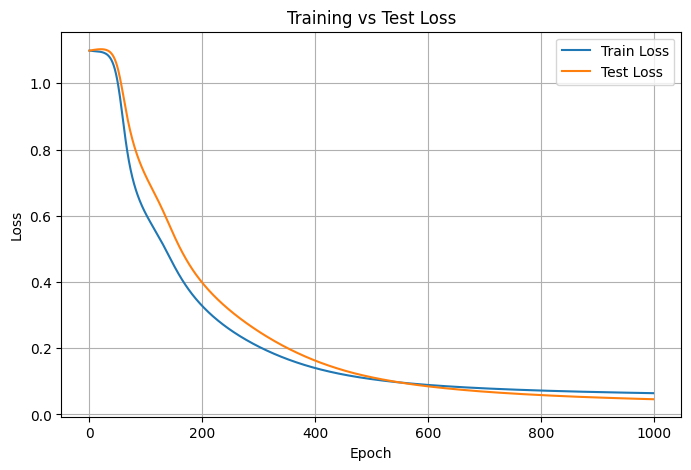

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history, label="Train Loss")
plt.plot(test_loss_history, label="Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Test Loss")
plt.legend()

plt.grid(True)
plt.show()

In [ ]:
# Run a final forward pass on the held-out test set to generate predictions
_, _, _, predictions = forward(X_test)

predicted_classes = np.argmax(predictions, axis=1)

accuracy = np.mean(predicted_classes == y_test)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 100.00%


In [ ]:
# Compare actual vs predicted class indices side by side
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predicted_classes
})

results

,Actual,Predicted
0,1,1
1,0,0
2,1,1
3,1,1
4,0,0
5,1,1
6,2,2
7,2,2
8,0,0
9,1,1


In [ ]:
class_names = {
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
}

# Map numeric labels back to readable species names for easier interpretation
results["Actual Species"] = results["Actual"].map(class_names)
results["Predicted Species"] = results["Predicted"].map(class_names)

results

,Actual,Predicted,Actual Species,Predicted Species
0,1,1,Versicolor,Versicolor
1,0,0,Setosa,Setosa
2,1,1,Versicolor,Versicolor
3,1,1,Versicolor,Versicolor
4,0,0,Setosa,Setosa
5,1,1,Versicolor,Versicolor
6,2,2,Virginica,Virginica
7,2,2,Virginica,Virginica
8,0,0,Setosa,Setosa
9,1,1,Versicolor,Versicolor


In [ ]:
# Show the full softmax probability vector for each test sample alongside the prediction
prediction_probabilities = forward(X_test)[3]

for i in range(len(X_test)):
    print(
        f"Actual: {class_names[y_test[i]]}, "
        f"Predicted: {class_names[predicted_classes[i]]}, "
        f"Probabilities: {prediction_probabilities[i]}"
    )

Actual: Versicolor, Predicted: Versicolor, Probabilities: [0.00492574 0.97477284 0.02030142]
Actual: Setosa, Predicted: Setosa, Probabilities: [0.7855627  0.21223657 0.00220073]
Actual: Versicolor, Predicted: Versicolor, Probabilities: [0.0031489  0.98842863 0.00842247]
Actual: Versicolor, Predicted: Versicolor, Probabilities: [0.00321925 0.98910405 0.0076767 ]
Actual: Setosa, Predicted: Setosa, Probabilities: [9.99839981e-01 1.49528282e-04 1.04905665e-05]
Actual: Versicolor, Predicted: Versicolor, Probabilities: [0.00651732 0.98287014 0.01061254]
Actual: Virginica, Predicted: Virginica, Probabilities: [9.24963219e-05 5.42807716e-03 9.94479427e-01]
Actual: Virginica, Predicted: Virginica, Probabilities: [1.95456314e-04 5.86398818e-03 9.93940556e-01]
Actual: Setosa, Predicted: Setosa, Probabilities: [9.99805446e-01 1.80988097e-04 1.35654181e-05]
Actual: Versicolor, Predicted: Versicolor, Probabilities: [0.00743842 0.98600994 0.00655164]
Actual: Virginica, Predicted: Virginica, Probabili

## 6. Conclusion

A feedforward neural network was successfully implemented from scratch using Python and NumPy without using in-built deep learning libraries.

The network used a 4-8-3 architecture with ReLU activation in the hidden layer and Softmax activation in the output layer.

Forward propagation was used to generate predictions, while backpropagation calculated the gradients. Gradient descent was used to update the weights and biases.

The training and test sets were normalized using statistics computed only from the training data, avoiding data leakage. The decreasing training and test loss, together with the final test accuracy, demonstrate that the neural network successfully learned to classify the Iris dataset into three different species.

## GitHub Repository

GitHub Repository: **https://github.com/nahushdeshmukh17/GenerativeAI-NN**

## Declaration

I, **Nahush Pramod Deshmukh**, confirm that the work submitted in this assignment is my own and has been completed following academic integrity guidelines.

The code is uploaded on my GitHub repository and the repository link is provided above.

**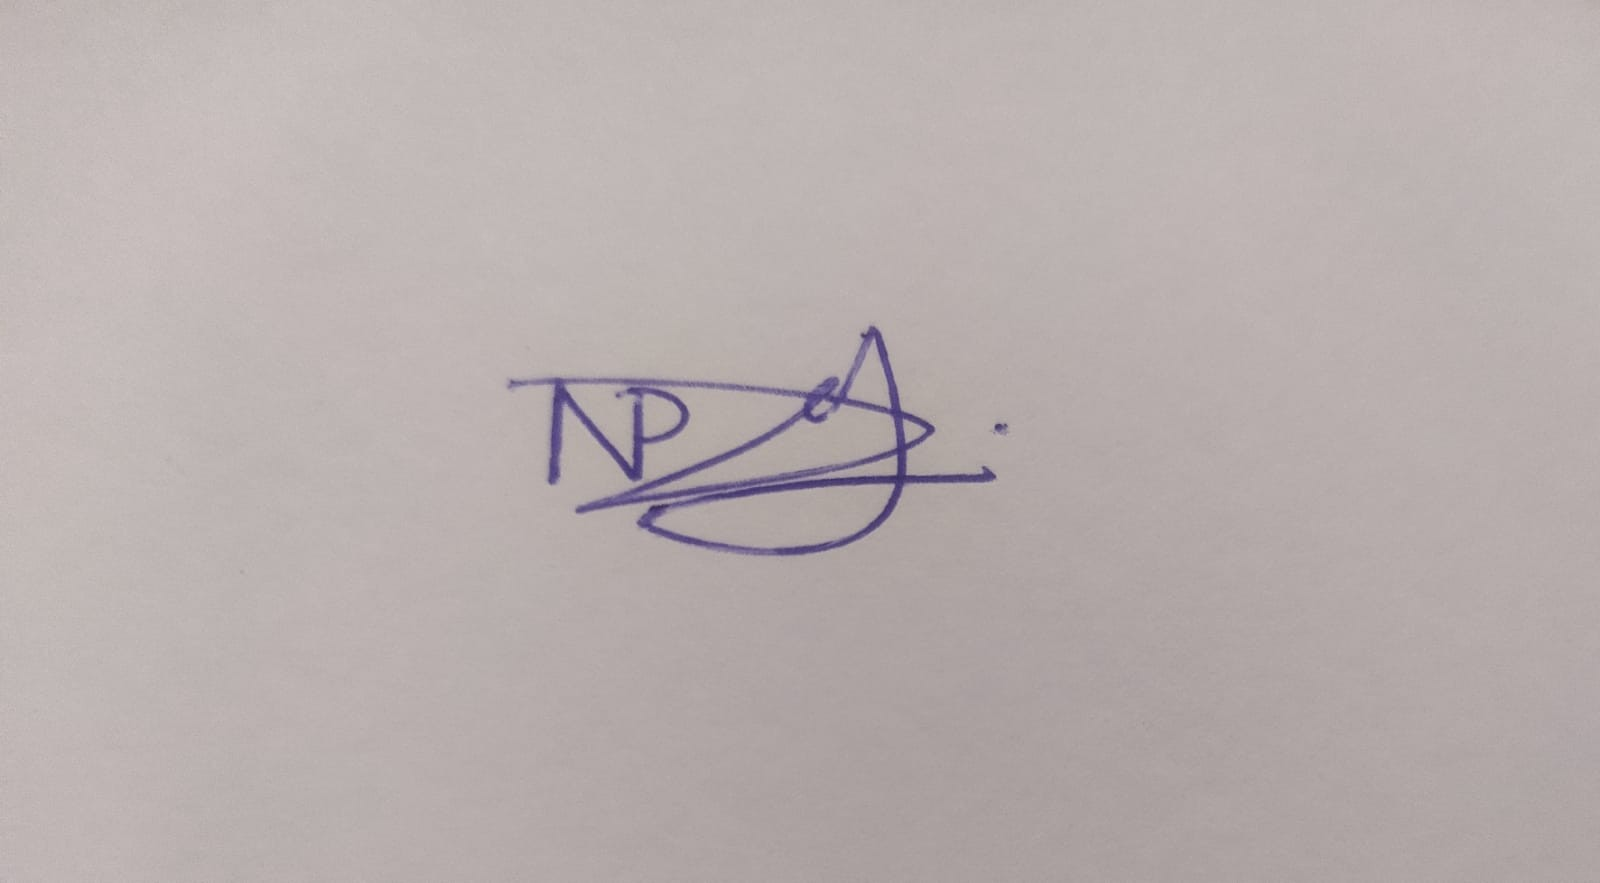Signature:** [Nahush Pramod Deshmukh]